## Excercise 1 - Plotting

### Task 1: 

Choose whatever mathematical function you want (e.g. sin(x), log(x), exp(x), etc.)
and plot it. Change the linestyle, thickness and color of the curve. Add axis labels and a title
to your plot.

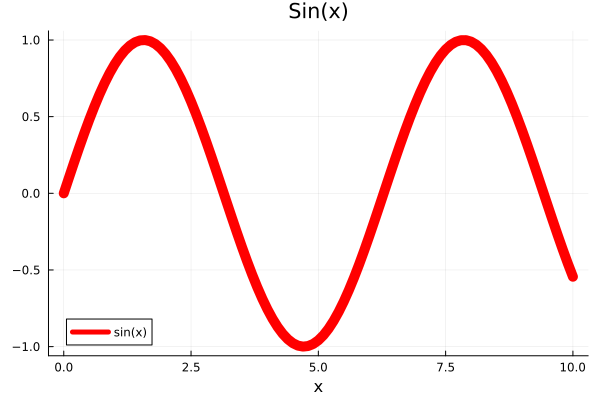

In [3]:
# import Pkg; Pkg.add("Plots")

x = range(0, 10,step=0.1)
y = sin.(x)

using Plots

plot(x, y, label = "sin(x)", color = :red, linewidth = 10)
plot!(title = "Sin(x)", xlabel = "x")

### Task 2: 

Choose a second function and plot it in the same figure as the function you chose in
task 1. Add labels to both functions and include a legend in your plot.

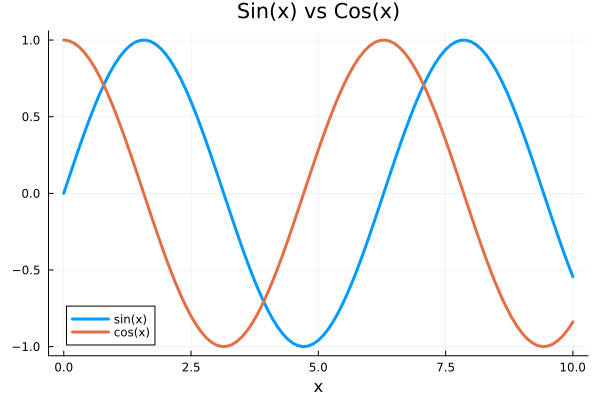

In [2]:
z = cos.(x)

using Plots

y1 = sin.(x)
y2 = cos.(x)
plot(x, [y1 y2], title="Sin(x) vs Cos(x)", label=["sin(x)" "cos(x)"], linewidth=3)
plot!(xlabel="x")


## Assume that we have some data

```julia
xdata = [
    15.2; 19.9; 2.2; 11.8; 12.1; 18.1; 11.8; 13.4; 11.5; 0.5;
    18.0; 10.2; 10.6; 13.8; 4.6; 3.8; 15.1; 15.1; 11.7; 4.2
]

ydata = [
    0.73; 0.19; 1.54; 2.08; 0.84; 0.42; 1.77; 0.86; 1.95; 0.27;
    0.39; 1.39; 1.25; 0.76; 1.99; 1.53; 0.86; 0.52; 1.54; 1.05
]
```

And a function of the form

$$
f(x) = \beta_1 \left(\frac{x}{\beta_2}\right)
\exp\left[-\left(\frac{x}{\beta_2}\right)^{\beta_3}\right].
$$


### Task 1

Find the vector $\boldsymbol{\beta}$ that best fits the data using the package `LsqFit` and quantify the fit quality.

**Hint:** The `LsqFit` package can be installed in the same way as the `IJulia` package (see section *"Setting up Julia"* below).

In [26]:
# import Pkg; Pkg.add("LsqFit")

using LsqFit
using Statistics

xdata = [
    15.2; 19.9; 2.2; 11.8; 12.1; 18.1; 11.8; 13.4; 11.5; 0.5;
    18.0; 10.2; 10.6; 13.8; 4.6; 3.8; 15.1; 15.1; 11.7; 4.2
]

ydata = [
    0.73; 0.19; 1.54; 2.08; 0.84; 0.42; 1.77; 0.86; 1.95; 0.27;
    0.39; 1.39; 1.25; 0.76; 1.99; 1.53; 0.86; 0.52; 1.54; 1.05
]


f(x, β) = β[1] * (x/β[2]) .* exp.(-(x/β[2]).^β[3])

p0 = [1.0, 5.0, 1.0]

fit = curve_fit(f, xdata, ydata, p0)
β = fit.param

y_pred = f(xdata, β)

mse = mean((ydata-y_pred).^2)
rmse = sqrt(mse)

println("Fitted parameters: ", β)
println("MSE: $mse")
println("RMSE: $rmse")

Fitted parameters: [4.748982099918662, 9.831266158159108, 1.8938402290750598]
MSE: 0.11264560216771136
RMSE: 0.33562717733775876


### Task 2

Plot the raw data and the fitting function.

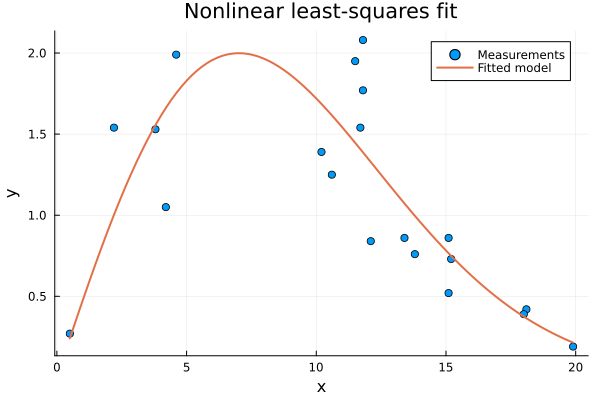

In [27]:
x_plot = range(minimum(xdata), maximum(xdata); length=100)

scatter(xdata, ydata;
    label="Measurements",
    xlabel="x",
    ylabel="y",
    title="Nonlinear least-squares fit",
)

plot!(x_plot, f(x_plot, β);
    label="Fitted model",
    linewidth=2,
)